## Loading Data

In [8]:
"""
from sklearn.datasets import fetch_openml

data = fetch_openml(data_id=1597, as_frame=True)

X = data.data
y = data.target

df = pd.DataFrame(data)
"""

'\nfrom sklearn.datasets import fetch_openml\n\ndata = fetch_openml(data_id=1597, as_frame=True)\n\nX = data.data\ny = data.target\n\nprint("Number of observations:", X.shape[0])\nprint("Number of input features:", X.shape[1])\nprint("Class distribution:")\nprint(y.value_counts())\nprint("Missing values:", X.isna().sum().sum())\n'

In [1]:
import pandas as pd
from scipy.io import arff

data, meta = arff.loadarff("creditcard.arff")
df = pd.DataFrame(data)

print(df.head())

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [2]:
print("Number of observations:", df.shape[0])
print("Number of input features:", df.shape[1] - 1)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isna().sum().sum())

print("\nClass distribution:")
print(df["Class"].value_counts())

Number of observations: 284807
Number of input features: 30

Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Missing values:
0

Class distribution:
Class
b'0'    284315
b'1'       492
Name: count, dtype: int64


In [3]:
df["Class"] = df["Class"].str.decode("utf-8").astype(int)

In [4]:
X = df.drop(columns=["Class"])
y = df["Class"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (284807, 30)
y shape: (284807,)


## Baseline

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTest class distribution:")
print(y_test.value_counts())


Training set: (227845, 30)
Test set: (56962, 30)

Training class distribution:
Class
0    227451
1       394
Name: count, dtype: int64

Test class distribution:
Class
0    56864
1       98
Name: count, dtype: int64


In [8]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight=None,
        random_state=42
    ))
])

param_grid = {
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100]
}

inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="average_precision",
    cv=inner_cv,
    n_jobs=1,
    refit=True
)


In [9]:
grid_search.fit(X_train, y_train)

print("Best C:", grid_search.best_params_["model__C"])
print("Best mean CV AP:", grid_search.best_score_)

results = pd.DataFrame(grid_search.cv_results_)

print("\nCross-validation results:")
print(results[[
    "param_model__C",
    "mean_test_score",
    "std_test_score"
]])


Best C: 10
Best mean CV AP: 0.762682207844266

Cross-validation results:
   param_model__C  mean_test_score  std_test_score
0           0.001         0.760320        0.045392
1           0.010         0.760542        0.045345
2           0.100         0.761713        0.042704
3           1.000         0.761497        0.041113
4          10.000         0.762682        0.040199
5         100.000         0.762458        0.039901


In [10]:
import numpy as np
from sklearn.base import clone
from sklearn.metrics import average_precision_score

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)

y_train_array = np.asarray(y_train).astype(int)

# Store out-of-fold predicted probabilities
oof_probs = np.zeros(len(y_train_array))

outer_scores = []
outer_best_C = []

for fold, (train_idx, val_idx) in enumerate(
    outer_cv.split(X_train, y_train_array), start=1
):
    X_outer_train = X_train.iloc[train_idx]
    X_outer_val = X_train.iloc[val_idx]

    y_outer_train = y_train_array[train_idx]
    y_outer_val = y_train_array[val_idx]

    # Tune C using only the outer training fold
    model = clone(grid_search)
    model.fit(X_outer_train, y_outer_train)

    # Predict on unseen outer validation data
    probs = model.predict_proba(X_outer_val)[:, 1]

    oof_probs[val_idx] = probs

    fold_ap = average_precision_score(
        y_outer_val, probs
    )

    outer_scores.append(fold_ap)
    outer_best_C.append(model.best_params_["model__C"])

    print(
        f"Fold {fold}: "
        f"AP = {fold_ap:.4f}, "
        f"Best C = {outer_best_C[-1]}"
    )

# Calculate AP across all out-of-fold predictions
baseline_ap = average_precision_score(
    y_train_array, oof_probs
)

print(f"\nPooled out-of-fold AP: {baseline_ap:.4f}")
print(f"Mean outer-fold AP: {np.mean(outer_scores):.4f}")


Fold 1: AP = 0.7369, Best C = 100
Fold 2: AP = 0.6562, Best C = 1
Fold 3: AP = 0.8431, Best C = 100
Fold 4: AP = 0.8006, Best C = 0.1
Fold 5: AP = 0.7770, Best C = 1

Pooled out-of-fold AP: 0.7617
Mean outer-fold AP: 0.7628


In [11]:
rng = np.random.default_rng(42)

n_bootstrap = 1000

bootstrap_scores = []

# Separate positive and negative indices
positive_idx = np.where(y_train_array == 1)[0]
negative_idx = np.where(y_train_array == 0)[0]

for i in range(n_bootstrap):

    # Sample each class with replacement
    sampled_positive = rng.choice(
        positive_idx,
        size=len(positive_idx),
        replace=True
    )

    sampled_negative = rng.choice(
        negative_idx,
        size=len(negative_idx),
        replace=True
    )

    indices = np.concatenate([
        sampled_positive,
        sampled_negative
    ])

    # Calculate AP for the bootstrap sample
    score = average_precision_score(
        y_train_array[indices],
        oof_probs[indices]
    )

    bootstrap_scores.append(score)

bootstrap_scores = np.array(bootstrap_scores)

# Percentile confidence interval
ci_lower, ci_upper = np.percentile(
    bootstrap_scores,
    [2.5, 97.5]
)

print(f"Baseline AP: {baseline_ap:.4f}")
print(f"95% Bootstrap CI: [{ci_lower:.4f}, {ci_upper:.4f}]")


Baseline AP: 0.7617
95% Bootstrap CI: [0.7180, 0.8035]


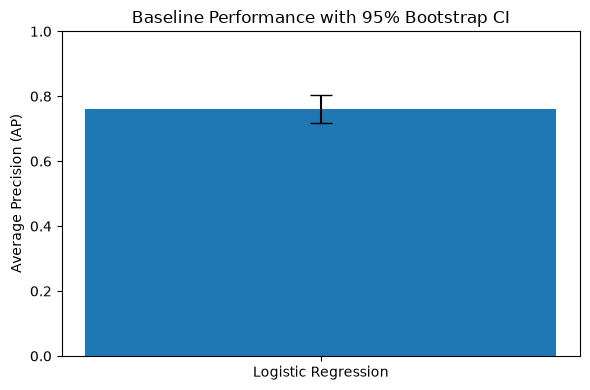

In [12]:
import matplotlib.pyplot as plt

# Confidence interval can be asymmetric
lower_error = baseline_ap - ci_lower
upper_error = ci_upper - baseline_ap

plt.figure(figsize=(6, 4))

plt.bar(
    ["Logistic Regression"],
    [baseline_ap],
    yerr=np.array([
        [lower_error],
        [upper_error]
    ]),
    capsize=8
)

plt.ylabel("Average Precision (AP)")
plt.title("Baseline Performance with 95% Bootstrap CI")
plt.ylim(0, 1)

plt.tight_layout()
plt.savefig("baseline.png", dpi=300)
plt.show()


In [13]:

print("=== BASELINE CHECKPOINT ===")

print("\nModel: Logistic Regression")
print("Class weighting: None")
print("Resampling: None")
print("Scaling: StandardScaler")

print("\nHyperparameter grid:")
print(param_grid)

print("\nSelected C (full training data):")
print(grid_search.best_params_["model__C"])

print("\nOuter-fold AP scores:")
for i, score in enumerate(outer_scores, start=1):
    print(f"Fold {i}: {score:.4f}")

print(f"\nPooled out-of-fold AP: {baseline_ap:.4f}")

print(
    f"95% Bootstrap CI: "
    f"[{ci_lower:.4f}, {ci_upper:.4f}]"
)

print("\nBootstrap resamples:", n_bootstrap)
print("Random seed: 42")
print("Final test set used: No")


=== BASELINE CHECKPOINT ===

Model: Logistic Regression
Class weighting: None
Resampling: None
Scaling: StandardScaler

Hyperparameter grid:
{'model__C': [0.001, 0.01, 0.1, 1, 10, 100]}

Selected C (full training data):
10

Outer-fold AP scores:
Fold 1: 0.7369
Fold 2: 0.6562
Fold 3: 0.8431
Fold 4: 0.8006
Fold 5: 0.7770

Pooled out-of-fold AP: 0.7617
95% Bootstrap CI: [0.7180, 0.8035]

Bootstrap resamples: 1000
Random seed: 42
Final test set used: No
